# 02 — Sensitivity analysis

The factorial screen varies IT capacity, coolant outlet temperature, outdoor temperature, and the fraction of heat entering the recovery loop.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sensitivity = pd.read_csv(ROOT / 'results' / 'sensitivity_results.csv')
sensitivity.shape, sensitivity.head()

((144, 30),
                                         scenario_id  \
 0  load_1mw_source_25c_outdoor_-10c_collection_0.40   
 1  load_1mw_source_25c_outdoor_-10c_collection_0.60   
 2  load_1mw_source_25c_outdoor_-10c_collection_0.75   
 3  load_1mw_source_25c_outdoor_-10c_collection_0.90   
 4    load_1mw_source_25c_outdoor_0c_collection_0.40   
 
                        description  it_capacity_mw  it_load_fraction  \
 0  Factorial sensitivity screening             1.0               0.8   
 1  Factorial sensitivity screening             1.0               0.8   
 2  Factorial sensitivity screening             1.0               0.8   
 3  Factorial sensitivity screening             1.0               0.8   
 4  Factorial sensitivity screening             1.0               0.8   
 
    heat_conversion_fraction  collection_fraction  \
 0                       1.0                 0.40   
 1                       1.0                 0.60   
 2                       1.0                 0.75  

In [2]:
screen = sensitivity[(sensitivity.it_capacity_mw == 10) & (sensitivity.collection_fraction == 0.75)]
screen.pivot_table(index='outdoor_temp_c', columns='coolant_outlet_temp_c', values='supported_area_m2').round(0)

coolant_outlet_temp_c,25.0,35.0,45.0,55.0
outdoor_temp_c,,,,
-10.0,23334.0,23111.0,19259.0,19259.0
0.0,36297.0,35950.0,29958.0,29958.0
10.0,81667.0,80888.0,67407.0,67407.0


A large source stream does not guarantee a large greenhouse. Cold outdoor temperatures, a leaky envelope, exchanger performance, distance, and the need for a heat pump can dominate the result.

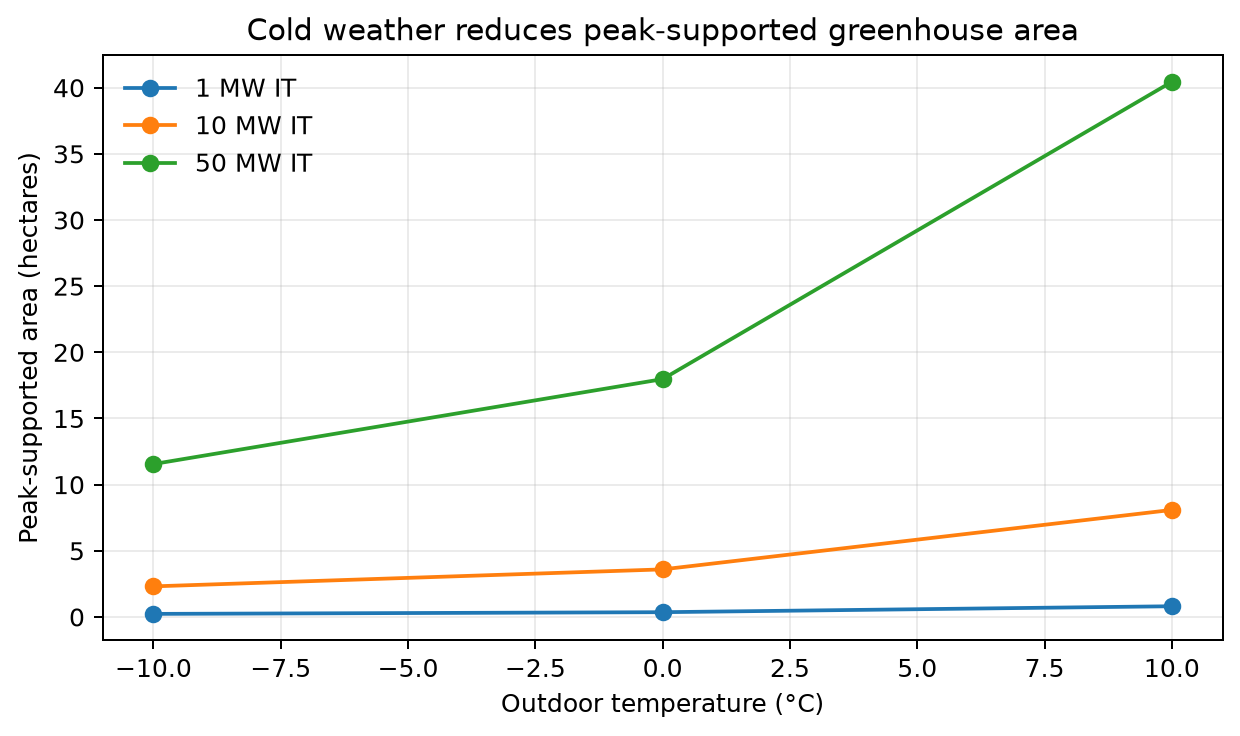

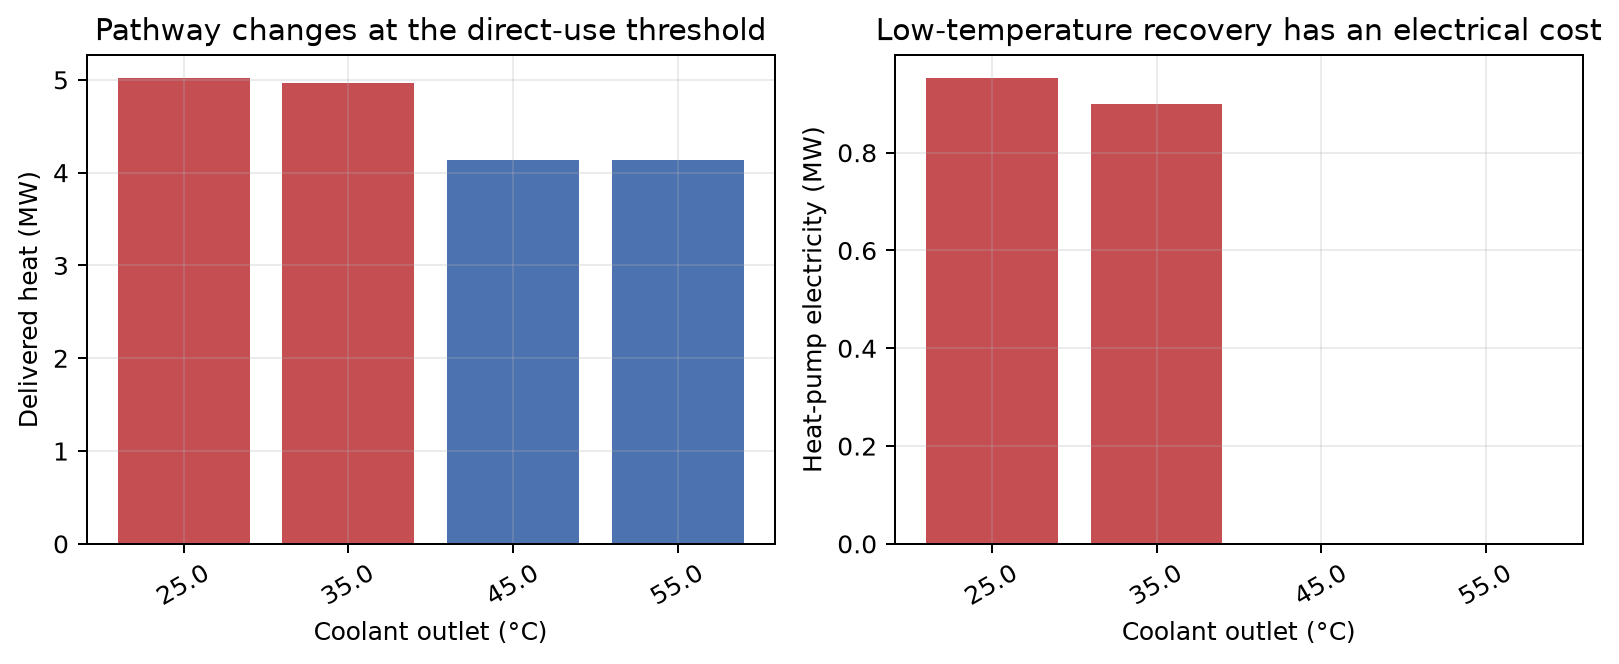

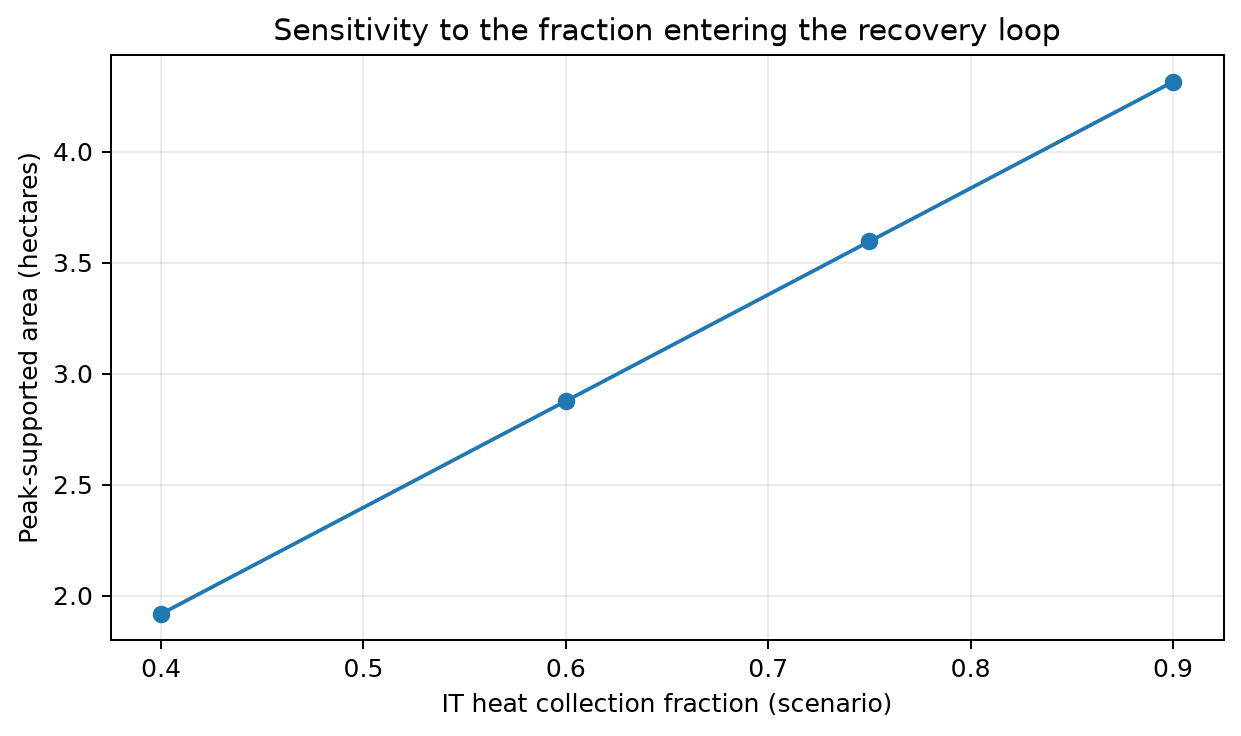

In [3]:
display(Image(filename=str(ROOT / 'figures' / 'supported_area_vs_outdoor_temperature.png')))
display(Image(filename=str(ROOT / 'figures' / 'direct_vs_heat_pump.png')))
display(Image(filename=str(ROOT / 'figures' / 'sensitivity_collection_fraction.png')))